# TokenGate inference: original implementation and vLLM

[TokenGate](https://arxiv.org/abs/2610.26754) learns which prompt tokens to keep for later model layers. This notebook uses the released [Qwen3-1.7B](https://huggingface.co/liana313/tokengate-niah-qwen3-1.7b) and [Qwen3.5-2B](https://huggingface.co/liana313/tokengate-niah-qwen3.5-2b) checkpoints to retrieve a fact from a long text, then compares accuracy, latency and throughput across implementations.

The retained-token budget $K$ counts tokens kept from the text. Instructions and the question remain protected. We evaluate $K=64$, $512$, $2{,}048$, $4{,}096$, $8{,}192$, and **All**. **All** keeps the full prompt and still applies TokenGate's learned attention adjustments. Base Qwen processes the full prompt without the trained gate or adapter.

Sections 2–4 walk through one example. Section 5 measures the latency–accuracy trade-off on 184 held-out examples. Section 6 measures how throughput and latency change with batch size and concurrency.


## 1. Set up

Use Linux with an idle NVIDIA GPU, a CUDA toolkit with `nvcc`, a C++ compiler, Git, and [uv](https://docs.astral.sh/uv/). From the TokenGate repository root, install the notebook dependencies and build TokenGate's attention kernel:

```bash
uv venv --python 3.12 --seed .venv
uv pip install --python .venv/bin/python --torch-backend=auto -e '.[benchmark]' ipykernel matplotlib-inline
.venv/bin/python kernels/fa2bias/build.py
```

Select `.venv/bin/python` as the notebook kernel.

Setup downloads the [TokenGate vLLM fork](https://github.com/luis-gasparschroeder/vllm/tree/lgs/tokengate) into a temporary directory and installs it in a separate Python environment. `VLLM_REVISION` pins the published commit for this setup. The first run needs internet access and time to install dependencies.

Set `GPU` to an idle device. If TokenGate's attention kernel is already built for your PyTorch/CUDA environment, set `FA2BIAS_SITE` to that build. Both checkpoints are public; no Hugging Face token is needed.

By default, the notebook runs new measurements and saves them under `results/vllm-benchmark/`. The full evaluation and batching sweep can take several hours. The saved outputs in this notebook can also be viewed without executing it.

To replay measurements, set `TOKEN_GATE_SAVED_RUNS`, `TOKEN_GATE_TEST_RUNS` and `TOKEN_GATE_BATCH_RUNS` to JSON lists of completed run directories before starting the kernel. For batching evidence with a source selection manifest, set `TOKEN_GATE_BATCH_SELECTION` to its path instead of `TOKEN_GATE_BATCH_RUNS`. Replay validates the recorded inputs, checkpoints and source identities and needs no GPU when all three sections have saved runs.


In [1]:
import os
from datetime import datetime, timezone
from pathlib import Path
from runpy import run_path

ROOT = Path.cwd().resolve()
if ROOT.name == "examples":
    ROOT = ROOT.parent
os.chdir(ROOT)
helpers = run_path(str(ROOT / "examples/inference-vllm-helper.py"))

VLLM_REPOSITORY = "https://github.com/luis-gasparschroeder/vllm.git"
VLLM_BRANCH = "lgs/tokengate"
VLLM_REVISION = "27b09ea73246000f37a6700f72c396c9c2e1abd9"
GPU = "0"
N_EXAMPLES = 1
WARMUPS = 2
REPEATS = 5
PROFILE = False  # Capture an extra, untimed full-context trace per implementation.
ENGINES = ["original", "vllm", "vllm_tiled", "vllm_base", "vllm_base_triton"]
CONFIGS = [
    ROOT / "benchmarks/configs/vllm_niah_qwen3.yaml",
    ROOT / "benchmarks/configs/vllm_niah_qwen3_5.yaml",
]
# Optional: a JSON list of completed run directories; unset to run inference.
SAVED_RUNS = helpers["saved_run_paths"]("TOKEN_GATE_SAVED_RUNS")
TEST_SAVED_RUNS = helpers["saved_run_paths"]("TOKEN_GATE_TEST_RUNS")
BATCH_RUNS, BATCH_SOURCES = helpers["saved_batching_runs"]()
OUTPUT = (
    SAVED_RUNS[0].parent if SAVED_RUNS
    else ROOT / "results/vllm-benchmark" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ")
)

RUNTIME = {"gpu": GPU}
if not (SAVED_RUNS and TEST_SAVED_RUNS and BATCH_RUNS):
    RUNTIME.update(helpers["prepare_vllm_runtime"](VLLM_REPOSITORY, VLLM_BRANCH, VLLM_REVISION))

### Check the hardware

The next cell reports the CPU, memory, GPU and software configuration recorded for the measurements, or the current hardware when running inference.


In [2]:
helpers["show_hardware"](SAVED_RUNS, GPU)

              Inference hardware: Qwen3-1.7B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 0                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

              Inference hardware: Qwen3.5-2B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 1                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

## 2. Inspect the checkpoints and example

Each released checkpoint contains a **gate**, which scores prompt tokens, and a **LoRA adapter**, which stores learned updates to Qwen's weights. TokenGate inference uses both. Qwen3 places the gate after layer 1; Qwen3.5 uses layer 3, counting from zero.

We use a 32K needle-in-a-haystack example. The question appears before the text so the gate can use it when choosing tokens. Increase `N_EXAMPLES` to include more of the five examples provided with the repository.


In [3]:
helpers["show_checkpoints"](CONFIGS)
sample = helpers["show_example"](ROOT / "examples/data/niah_32k_samples.jsonl", N_EXAMPLES)

                                       Published checkpoints                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Gate layer ┃ Checkpoint                         ┃ Budgets                           ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 1          │ liana313/tokengate-niah-qwen3-1.7b │ 64, 512, 2,048, 4,096, 8,192, All │
│ Qwen3.5-2B │ 3          │ liana313/tokengate-niah-qwen3.5-2b │ 64, 512, 2,048, 4,096, 8,192, All │
└────────────┴────────────┴────────────────────────────────────┴───────────────────────────────────┘

Question: What is the best thing to do in San Francisco?

Expected answer: eat a sandwich and sit in Dolores Park on a sunny day

Text preview: People who worry about the increasing gap between rich and poor generally look back on the mid twentieth century as a golden 
age. In those days we had a large number of high-paying union manufacturing jobs that boosted the median income. I wouldn't quite call the 
high-paying union job a myth, but I think people who dwell on it are reading too much into it. Oddly enough, it was working with startups 
that made me realize where the high-paying union job came from. In a rapidly growing market, you d...

## 3. Run inference

The benchmark tokenizes each sample once per model. Every implementation receives the same token IDs and prunable span, $[s,e)$. Only tokens in that span compete for the $K$ places.

[The runner](../benchmarks/run_vllm_benchmark.py) defines the inference calls and shared end-of-sequence settings; [the vLLM backend](../benchmarks/vllm_backend.py) configures the engine. Each model is loaded once per implementation. Model loading and warmups are excluded from timing. The original worker checks that streaming preserves the output tokens and retained positions.


In [4]:
runs = helpers["run_benchmarks"](
    CONFIGS, OUTPUT, saved_runs=SAVED_RUNS, engines=ENGINES,
    n=N_EXAMPLES, warmups=WARMUPS, repeats=REPEATS, profile=PROFILE,
    **RUNTIME,
)

vllm_niah_qwen3: loaded 20 settings, 2 warmup(s), 5 timing repetitions.

vllm_niah_qwen3_5: loaded 20 settings, 2 warmup(s), 5 timing repetitions.

Using saved measurements; inference will not run again.

## 4. Compare the answers

We compare five implementations:

| Implementation | Model setup | Attention implementation |
| --- | --- | --- |
| **Original TokenGate** | Qwen with the trained gate and LoRA adapter | TokenGate's FlashAttention-2 kernels |
| **TokenGate in vLLM (Triton)** | The same trained gate and LoRA updates | Triton with TokenGate's learned attention adjustments |
| **TokenGate in vLLM (tiled prefill)** | The same trained gate and LoRA updates | Custom tiled prefill; paged Triton attention during generation |
| **Base Qwen in vLLM (auto)** | Pretrained Qwen | Backend selected by vLLM |
| **Base Qwen in vLLM (Triton)** | Pretrained Qwen | Triton |

The three TokenGate implementations run at all six retained-token budgets. Both Base Qwen baselines keep every prompt token and use the pretrained weights.

An answer is correct when it contains the expected phrase after normalization. Inspect the answer text alongside the score to see what the model retrieved.


In [5]:
helpers["show_answers"](runs, sample["id"], ENGINES)

                                                        Answers to the same question                                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Answer                                                   ┃ Correct ┃ Cap reached ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3.5-2B │ Original TokenGate                │ 64   │ eat a sandwich and sit on the puppet theater parkway on  │ no      │ no          │
│            │                                   │      │ a sunny day                                              │         │             │
│ Qwen3.5-2B │ Original TokenGate                │ 5

Qwen3-1.7B, original versus Triton: Generated tokens match at every tested budget.

Qwen3-1.7B, Triton versus tiled prefill: generated tokens match.

Qwen3.5-2B, original versus Triton: Generated tokens differ for at least one tested budget.

Qwen3.5-2B, Triton versus tiled prefill: generated tokens match.

## 5. Measure the latency–accuracy trade-off

We evaluate all **184 held-out 32K examples** at each budget with the same five implementations. The 16 validation examples are excluded.

**Time to first token (TTFT)** runs from submission of the prepared input tokens to arrival of the first generated token. **Time to final token** ends when the last token arrives. Downloads, model loading and warmups are excluded.

Grouped bars show these two latencies. Each pruned bar has a speedup label above it and retrieval accuracy below it. The speedup compares latency with the faster Base Qwen backend for that model; the dashed line marks this baseline. A **2.0×** speedup means half the baseline latency. Base Qwen appears at **K=All** because it processes the full prompt.

We take the median of three timed repetitions per example, then the median across examples. The table reports 95% bootstrap intervals for latency and Wilson intervals for accuracy. Each example contributes once to accuracy and must be correct in all three repetitions to count as correct.

The next cells select the reserved test IDs from the repository's NIAH pool and run the evaluation, or load saved measurements.


In [6]:
TEST_OUTPUT = TEST_SAVED_RUNS[0].parent if TEST_SAVED_RUNS else OUTPUT / "heldout"
TEST_SAMPLES = Path(os.environ.get(
    "TOKEN_GATE_TEST_SAMPLES",
    str(ROOT / "datasets/niah_kamradt/niah_kamradt_32k.jsonl"),
)).resolve()
test_ids = helpers["niah_test_ids"]()
test_configs = (
    helpers["prepare_niah_configs"](CONFIGS, TEST_SAMPLES, TEST_OUTPUT)
    if not TEST_SAVED_RUNS else []
)

Test split: 184 examples; 16 validation examples excluded.

In [7]:
test_runs = helpers["run_benchmarks"](
    test_configs, TEST_OUTPUT, saved_runs=TEST_SAVED_RUNS, engines=ENGINES,
    split="test", warmups=1, repeats=3, **RUNTIME,
)

qwen3-0: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-1: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-2: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen3-3: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-0: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-1: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-2: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

qwen35-3: loaded 20 settings, 1 warmup(s), 3 timing repetitions.

Using saved measurements; inference will not run again.

                             Held-out retrieval and first-token latency (95% intervals)                             
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Correct ┃ Accuracy             ┃ TTFT (ms)               ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 129.4 [129.3, 129.6]    │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 129.5 [129.3, 129.6]    │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 146.8 [146.7, 147.0]    │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 199.3 [199.2, 199.5]    │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 307.3 [307.1, 307.5]    │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 1316.7 [1315.3, 1322.1] │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 92.0 [91.9, 92.3]       │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 101.1 [101.0, 101.2]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 137.1 [136.9, 137.4]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 205.5 [205.3, 205.7]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 414.3 [414.2, 414.6]    │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 3620.1 [3612.8, 3627.9] │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ 184/184 │ 100.0% [98.0, 100.0] │ 91.7 [91.6, 91.8]       │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ 184/184 │ 100.0% [98.0, 100.0] │ 100.2 [100.1, 100.3]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ 184/184 │ 100.0% [98.0, 100.0] │ 126.2 [126.1, 126.4]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 164.7 [164.5, 164.9]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 259.7 [259.4, 260.0]    │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 1231.7 [1230.8, 1234.2] │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ 182/184 │ 98.9% [96.1, 99.7]   │ 1073.7 [1071.0, 1074.7] │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ 182/184 │ 98.9% [96.1, 99.7]   │ 2371.7 [2366.2, 2376.3] │
│ Qwen3.5-2B │ Original TokenGate                │ 64   │ 170/184 │ 92.4% [87.6, 95.4]   │ 188.7 [188.5, 188.8]    │
│ Qwen3.5-2B │ Original TokenGate                │ 512  │ 176/184 │ 95.7% [91.7, 97.8]   │ 188.8 [188.5, 189.0]    │
│ Qwen3.5-2B │ Original TokenGate                │ 2048 │ 183/184 │ 99.5% [97.0, 99.9]   │ 201.8 [201.6, 202.0]    │
│ Qwen3.5-2B │ Original TokenGate                │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 246.5 [246.4, 246.7]    │
│ Qwen3.5-2B │ Original TokenGate                │ 8192 │ 184/184 │ 100.0% [98.0, 100.0] │ 331.5 [331.2, 331.7]    │
│ Qwen3.5-2B │ Original TokenGate                │ All  │ 184/184 │ 100.0% [98.0, 100.0] │ 920.2 [918.9, 921.3]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 64   │ 170/184 │ 92.4% [87.6, 95.4]   │ 119.8 [119.6, 120.0]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 512  │ 176/184 │ 95.7% [91.7, 97.8]   │ 126.7 [126.5, 126.9]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 2048 │ 183/184 │ 99.5% [97.0, 99.9]   │ 149.6 [149.3, 149.7]    │
│ Qwen3.5-2B │ TokenGate in vLLM (Triton)        │ 4096 │ 184/184 │ 100.0% [98.0, 100.0] │ 181.6 [181.4, 181.9]    │
│ Qwen3.5-2B │ TokenGa

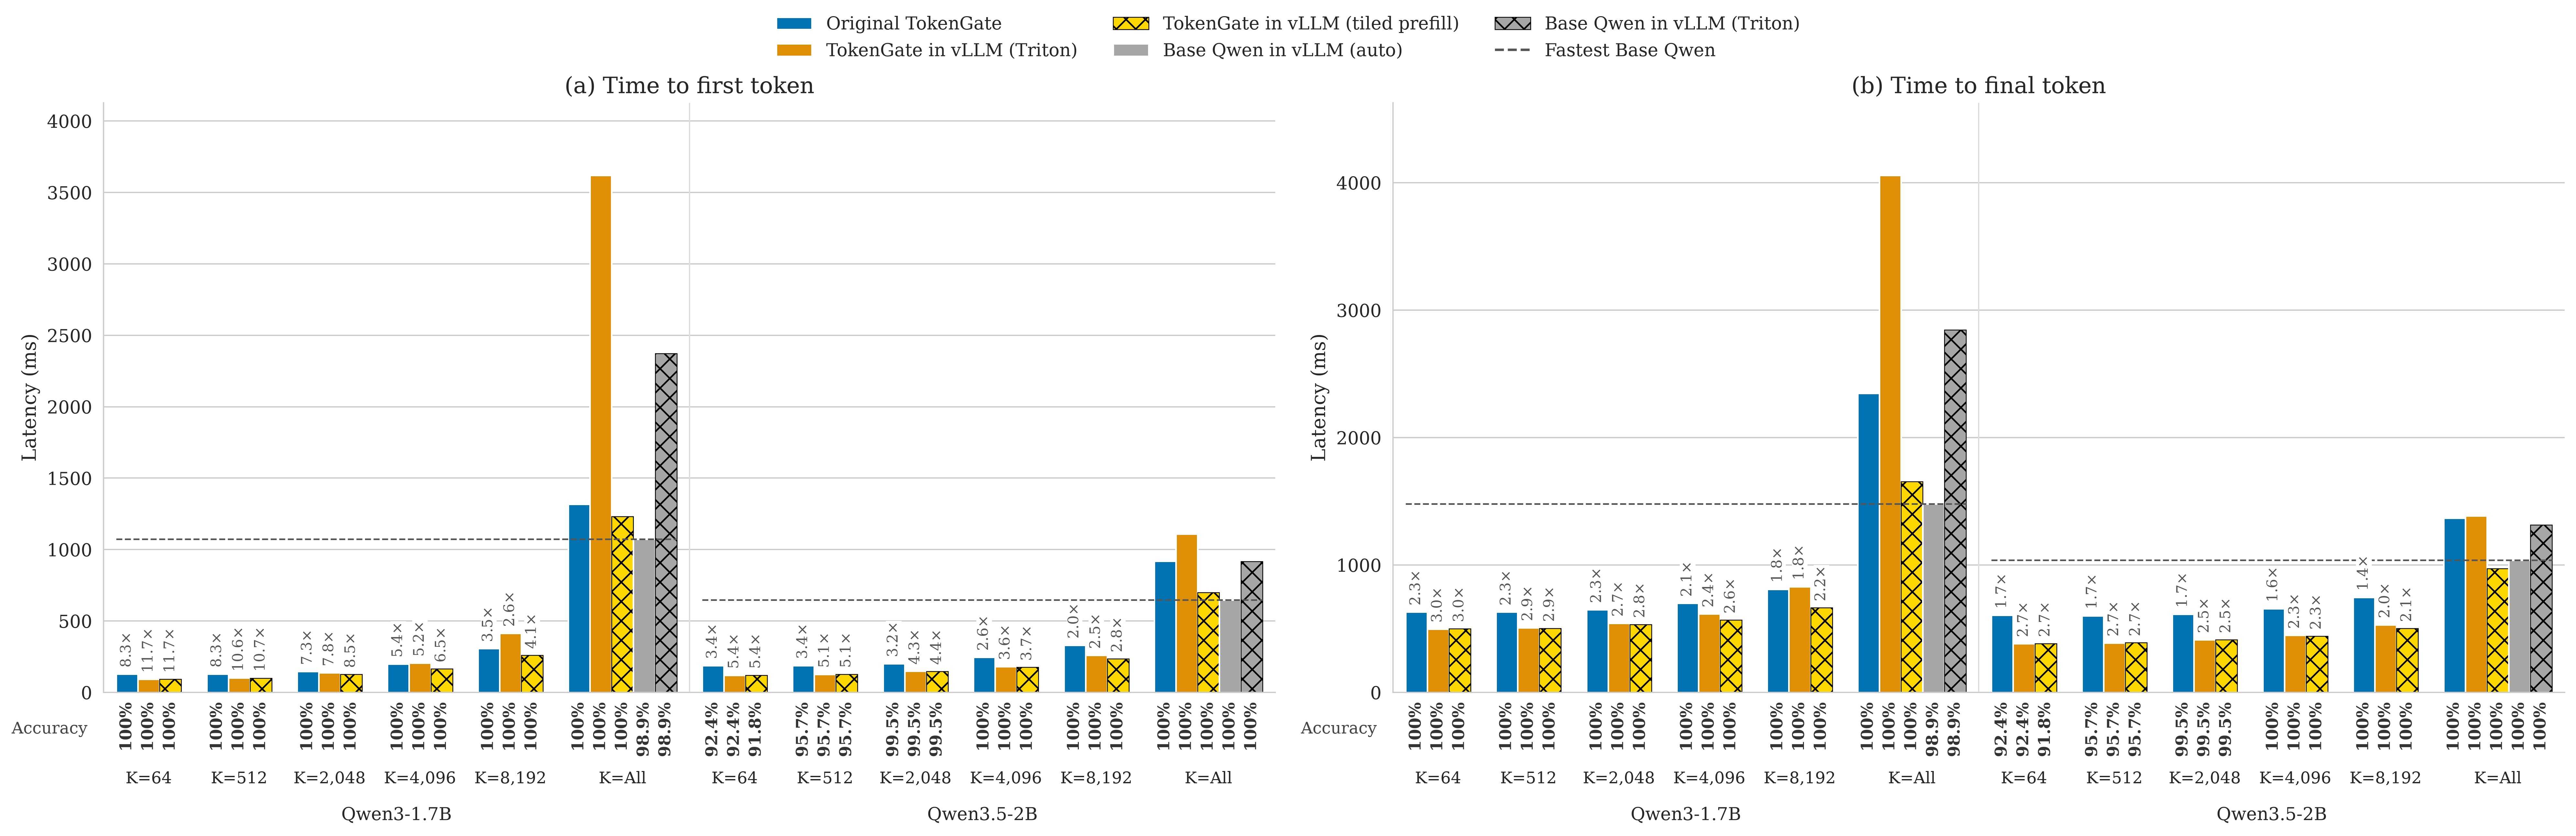

In [8]:
tradeoff = helpers["load_tradeoff"](test_runs, test_ids)
helpers["show_test_results"](tradeoff, CONFIGS, ENGINES, TEST_OUTPUT)
helpers["show_comparison"](tradeoff, TEST_OUTPUT / "latency-accuracy")

## 6. Measure batching throughput

**Batch size $B$** is the number of requests submitted together in a static batch. The next batch starts only after every request in the current batch finishes. **Concurrency $C$** is the maximum number of requests in flight: each completed request is replaced immediately while inputs remain. vLLM forms execution batches from these active requests, so $C$ need not equal the number processed in one model step.

We compare Original TokenGate, TokenGate in vLLM with **tiled prefill**, and Base Qwen in vLLM. The original implementation supports static batching; vLLM also supports continuous batching. The saved measurements use one A100 80 GB GPU; new measurements use the device selected in Section 1. The vLLM comparison uses matched settings: BF16, eager execution, complete prefill and no prefix caching. Base Qwen uses its automatically selected attention backend.

The 2×4 figure shows static batching above continuous batching, with **Qwen3-1.7B** in the left pair of columns and **Qwen3.5-2B** in the right pair. Each pair reports:

- **Throughput:** completed requests per second (higher is better).
- **p95 TTFT:** the time within which 95% of requests receive their first token, including queueing (lower is better).

Solid TokenGate lines use $K=2{,}048$; dotted lines in the same colors use $K=\mathrm{All}$. The solid gray line is Base Qwen, which retains the full prompt. Both budgets are measured at $B/C=1,2,4,8,16$.

Static measurements process all 184 test examples once per repetition. Continuous measurements use three 60-second windows after a 5-second ramp-up, cycling through the inputs to maintain load. Points show means over three repetitions, with 95% bootstrap intervals. Accuracy in the tables comes from separate finite passes over all 184 examples; an example must be correct in every repetition to count as correct.

At $C=16$, vertical brackets show **TokenGate/base throughput** and **base/TokenGate p95 TTFT** for tiled TokenGate at $K=2{,}048$. These ratios compare the three-run means. They measure end-to-end inference, including the generated answer lengths.


                                        Qwen3-1.7B, 184 test examples                                         
┏━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ Mode       ┃ B / C ┃ Implementation                    ┃ K    ┃ Settings ┃ Requests/s ┃ p95 TTFT ┃ Correct ┃
┡━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ continuous │ 1     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.67       │ 1083 ms  │ 182/184 │
│ continuous │ 1     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 1.89       │ 127 ms   │ 184/184 │
│ continuous │ 1     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.57       │ 1369 ms  │ 184/184 │
│ continuous │ 2     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.78       │ 1338 ms  │ 182/184 │
│ continuous │ 2     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 3.04       │ 236 ms   │ 184/184 │
│ continuous │ 2     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.64       │ 1882 ms  │ 184/184 │
│ continuous │ 4     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.80       │ 3146 ms  │ 182/184 │
│ continuous │ 4     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 4.38       │ 283 ms   │ 184/184 │
│ continuous │ 4     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.67       │ 6308 ms  │ 184/184 │
│ continuous │ 8     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.82       │ 8591 ms  │ 182/184 │
│ continuous │ 8     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 6.03       │ 415 ms   │ 184/184 │
│ continuous │ 8     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.66       │ 11110 ms │ 184/184 │
│ continuous │ 16    │ Base Qwen in vLLM                 │ All  │ matched  │ 0.79       │ 16619 ms │ 182/184 │
│ continuous │ 16    │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 7.14       │ 652 ms   │ 184/184 │
│ continuous │ 16    │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.64       │ 20160 ms │ 184/184 │
│ static     │ 1     │ Original TokenGate                │ 2048 │ matched  │ 1.49       │ 149 ms   │ 184/184 │
│ static     │ 1     │ Original TokenGate                │ All  │ matched  │ 0.42       │ 1340 ms  │ 184/184 │
│ static     │ 1     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.66       │ 1088 ms  │ 182/184 │
│ static     │ 1     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 1.82       │ 127 ms   │ 184/184 │
│ static     │ 1     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.56       │ 1375 ms  │ 184/184 │
│ static     │ 2     │ Original TokenGate                │ 2048 │ matched  │ 2.32       │ 290 ms   │ 184/184 │
│ static     │ 2     │ Original TokenGate                │ All  │ matched  │ 0.49       │ 2662 ms  │ 184/184 │
│ static     │ 2     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.76       │ 2146 ms  │ 182/184 │
│ static     │ 2     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 2.80       │ 238 ms   │ 184/184 │
│ static     │ 2     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.64       │ 2688 ms  │ 184/184 │
│ static     │ 4     │ Original TokenGate                │ 2048 │ matched  │ 3.40       │ 556 ms   │ 184/184 │
│ static     │ 4     │ Original TokenGate                │ All  │ matched  │ 0.54       │ 5437 ms  │ 184/184 │
│ static     │ 4     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.83       │ 4343 ms  │ 182/184 │
│ static     │ 4     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 4.11       │ 473 ms   │ 184/184 │
│ static     │ 4     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.67       │ 5426 ms  │ 184/184 │
│ static     │ 8     │ Original TokenGate                │ 2048 │ matched  │ 4.46       │ 1105 ms  │ 184/184 │
│ static     │ 8     │ Original TokenGate                │ All  │ matched  │ 0.56       │ 10698 ms │ 184/184 │
│ st

                                        Qwen3.5-2B, 184 test examples                                         
┏━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ Mode       ┃ B / C ┃ Implementation                    ┃ K    ┃ Settings ┃ Requests/s ┃ p95 TTFT ┃ Correct ┃
┡━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ continuous │ 1     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.96       │ 651 ms   │ 184/184 │
│ continuous │ 1     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 2.31       │ 150 ms   │ 183/184 │
│ continuous │ 1     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.02       │ 697 ms   │ 184/184 │
│ continuous │ 2     │ Base Qwen in vLLM                 │ All  │ matched  │ 1.17       │ 675 ms   │ 184/184 │
│ continuous │ 2     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 3.34       │ 286 ms   │ 183/184 │
│ continuous │ 2     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.18       │ 947 ms   │ 184/184 │
│ continuous │ 4     │ Base Qwen in vLLM                 │ All  │ matched  │ 1.32       │ 1291 ms  │ 184/184 │
│ continuous │ 4     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 4.57       │ 305 ms   │ 183/184 │
│ continuous │ 4     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.31       │ 1647 ms  │ 184/184 │
│ continuous │ 8     │ Base Qwen in vLLM                 │ All  │ matched  │ 1.38       │ 5720 ms  │ 184/184 │
│ continuous │ 8     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 5.50       │ 479 ms   │ 183/184 │
│ continuous │ 8     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.34       │ 5515 ms  │ 184/184 │
│ continuous │ 16    │ Base Qwen in vLLM                 │ All  │ matched  │ 1.33       │ 10602 ms │ 184/184 │
│ continuous │ 16    │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 6.52       │ 827 ms   │ 183/184 │
│ continuous │ 16    │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.31       │ 10919 ms │ 184/184 │
│ static     │ 1     │ Original TokenGate                │ 2048 │ matched  │ 1.66       │ 173 ms   │ 183/184 │
│ static     │ 1     │ Original TokenGate                │ All  │ matched  │ 0.80       │ 788 ms   │ 184/184 │
│ static     │ 1     │ Base Qwen in vLLM                 │ All  │ matched  │ 0.93       │ 654 ms   │ 184/184 │
│ static     │ 1     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 2.20       │ 150 ms   │ 183/184 │
│ static     │ 1     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 0.99       │ 700 ms   │ 184/184 │
│ static     │ 2     │ Original TokenGate                │ 2048 │ matched  │ 2.41       │ 348 ms   │ 183/184 │
│ static     │ 2     │ Original TokenGate                │ All  │ matched  │ 0.94       │ 1607 ms  │ 184/184 │
│ static     │ 2     │ Base Qwen in vLLM                 │ All  │ matched  │ 1.06       │ 1287 ms  │ 184/184 │
│ static     │ 2     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 3.28       │ 283 ms   │ 183/184 │
│ static     │ 2     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.17       │ 1372 ms  │ 184/184 │
│ static     │ 4     │ Original TokenGate                │ 2048 │ matched  │ 3.39       │ 683 ms   │ 183/184 │
│ static     │ 4     │ Original TokenGate                │ All  │ matched  │ 1.03       │ 3204 ms  │ 184/184 │
│ static     │ 4     │ Base Qwen in vLLM                 │ All  │ matched  │ 1.32       │ 2547 ms  │ 184/184 │
│ static     │ 4     │ TokenGate in vLLM (tiled prefill) │ 2048 │ matched  │ 4.38       │ 552 ms   │ 183/184 │
│ static     │ 4     │ TokenGate in vLLM (tiled prefill) │ All  │ matched  │ 1.30       │ 2712 ms  │ 184/184 │
│ static     │ 8     │ Original TokenGate                │ 2048 │ matched  │ 4.24       │ 1355 ms  │ 183/184 │
│ static     │ 8     │ Original TokenGate                │ All  │ matched  │ 1.09       │ 6405 ms  │ 184/184 │
│ st

TokenGate K=2,048 is solid; K=All is dotted. Base Qwen retains all tokens. Continuous throughput uses sustained windows when available. 
Accuracy in the tables counts each test example once.

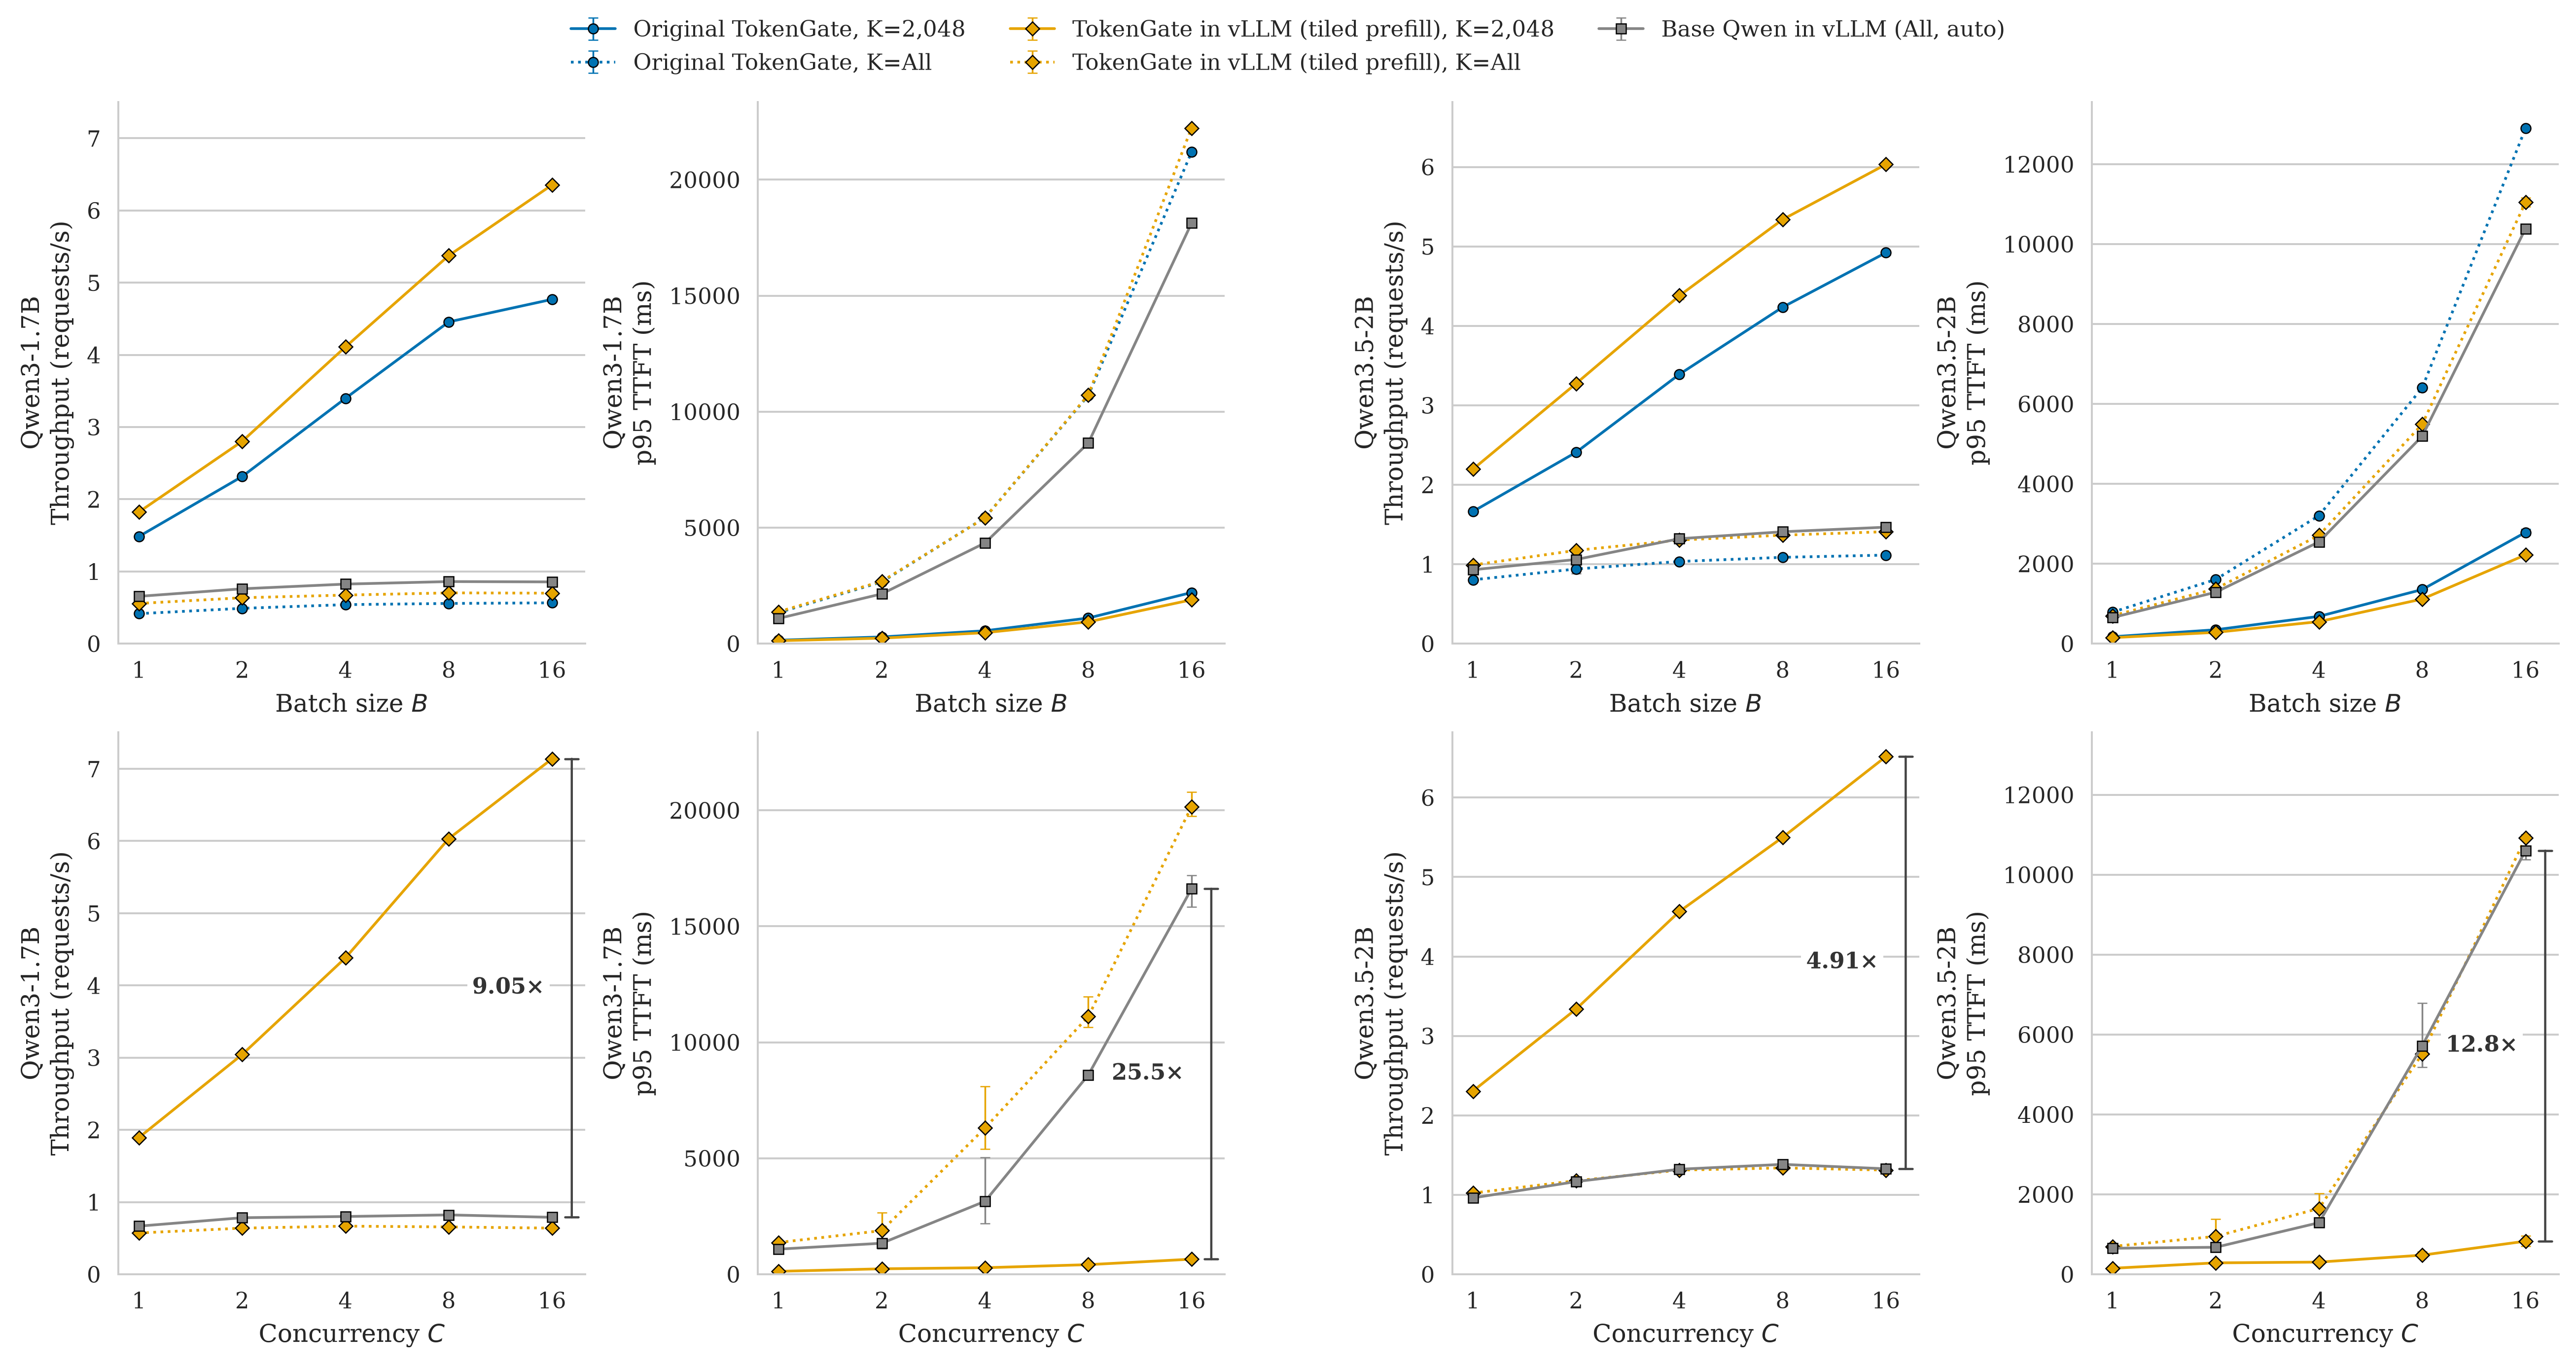

In [9]:
BATCH_K = 2048
if not BATCH_RUNS:
    BATCH_RUNS = helpers["run_batching_benchmarks"](
        CONFIGS, TEST_SAMPLES, OUTPUT / "batching-runs", budget=BATCH_K,
        **RUNTIME,
    )
batching = helpers["show_batching_results"](
    BATCH_RUNS, test_ids, OUTPUT / "batching", budget=BATCH_K,
    source_snapshots=BATCH_SOURCES,
)
